<a href="https://colab.research.google.com/github/benitezlucio/citi-bike-demand-intelligence/blob/main/notebooks/02_eda_insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Citi Bike Demand Intelligence
## 02 — Exploratory Data Analysis & Insights

### Objetivo

Identificar los factores temporales, climáticos y de comportamiento
asociados con la demanda de Citi Bike durante 2024.

A partir de los datasets preparados anteriormente, exploraremos
patrones de utilización, diferencias entre segmentos de usuarios,
condiciones meteorológicas y concentración de viajes por estación.

El análisis busca generar insights interpretables que puedan
contribuir a la planificación operativa y a la toma de decisiones.

### Alcance

- Período: enero a diciembre de 2024.
- Ubicación: Nueva York.
- Unidad principal de análisis: demanda horaria de viajes iniciados.
- Fuentes: Citi Bike Trip History y Open-Meteo.
- Metodología: EDA, visualizaciones y estadística descriptiva.

**Nota metodológica:** los resultados representan asociaciones
observadas y no necesariamente relaciones causales.

In [1]:
from pathlib import Path
import subprocess
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
REPO_NAME = "citi-bike-demand-intelligence"
REPO_URL = "https://github.com/benitezlucio/citi-bike-demand-intelligence.git"

def find_project_root(start):
    for path in (start, *start.parents):
        for candidate in (path, path / REPO_NAME):
            if (candidate / "notebooks" / "01_data_acquisition_preparation.ipynb").is_file():
                return candidate
    return None

PROJECT_ROOT = find_project_root(Path.cwd().resolve())

if PROJECT_ROOT is None and "google.colab" in sys.modules:
    PROJECT_ROOT = Path("/content") / REPO_NAME
    subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Repositorio no encontrado. Abrí el notebook desde el proyecto.")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)

PROJECT_ROOT: /content/citi-bike-demand-intelligence
PROCESSED_DIR: /content/citi-bike-demand-intelligence/data/processed


In [3]:
analysis_df = pd.read_csv(
    PROCESSED_DIR / "citibike_analysis_hourly_2024.csv",
    parse_dates=["datetime"]
)

segmented_df = pd.read_csv(
    PROCESSED_DIR / "citibike_segmented_hourly_2024.csv",
    parse_dates=["datetime"]
)

stations_df = pd.read_csv(
    PROCESSED_DIR / "citibike_stations_2024.csv"
)

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [4]:
datasets = {
    "Analysis": analysis_df,
    "Segmented": segmented_df,
    "Stations": stations_df
}

for name, df in datasets.items():
    print(f"{name}: shape={df.shape}, nulls={df.isna().sum().sum()}")

print("\nRide totals:")
for name, df in datasets.items():
    print(f"{name}: {df['ride_count'].sum():,}")

print("\nTemporal coverage:")
print("Start:", analysis_df["datetime"].min())
print("End:", analysis_df["datetime"].max())
print("Unique hours:", analysis_df["datetime"].nunique())

# Contrastamos los resultados con las validaciones del notebook 01.
assert len(analysis_df) == 8783
assert analysis_df["ride_count"].sum() == 44_302_480
assert segmented_df["ride_count"].sum() == 44_302_480
assert stations_df["ride_count"].sum() == 44_272_646
assert analysis_df["datetime"].is_unique
assert analysis_df["datetime"].notna().all()
assert not analysis_df.isna().any().any()

print("\nAll initial validations passed.")

Analysis: shape=(8783, 21), nulls=0
Segmented: shape=(35113, 13), nulls=0
Stations: shape=(4131, 3), nulls=0

Ride totals:
Analysis: 44,302,480
Segmented: 44,302,480
Stations: 44,272,646

Temporal coverage:
Start: 2024-01-01 00:00:00
End: 2024-12-31 23:00:00
Unique hours: 8783

All initial validations passed.


## 1. Descripción de los datos

El análisis utiliza tres datasets procesados a partir de Citi Bike
Trip History y Open-Meteo Historical Weather API.

| Dataset | Granularidad | Registros |
|---|---|---:|
| Analysis | Hora | 8.783 |
| Segmented | Hora × usuario × bicicleta | 35.113 |
| Stations | Estación de origen | 4.131 |

**Período:** 01/01/2024 – 31/12/2024.

**Volumen:** 44.302.480 viajes iniciados.

**Variable principal:** `ride_count`, cantidad de viajes iniciados.

Los datos horarios consideran el cambio de horario de verano
de Nueva York (DST), por lo que existen 8.783 timestamps locales
distintos en lugar de 8.784.

## 2. Preguntas e hipótesis

### H1 — Efecto del horario
¿Existen franjas horarias con mayor demanda?

Se espera observar picos de demanda asociados con los
horarios habituales de desplazamiento laboral.

### H2 — Laborables vs. fines de semana
¿Cambia el patrón de demanda según el tipo de día?

Los días laborales podrían presentar picos más marcados,
mientras que los fines de semana tendrían una distribución
horaria más uniforme.

### H3 — Member vs. Casual
¿Los distintos tipos de usuarios presentan patrones diferentes?

Se espera que los miembros concentren mayor actividad en
horarios laborales y los usuarios ocasionales durante
momentos recreativos.

### H4 — Condiciones climáticas
¿Cómo se relacionan las variables meteorológicas con la demanda?

Se espera una menor utilización durante precipitaciones,
temperaturas extremas y vientos fuertes.

### H5 — Estacionalidad
¿Cómo cambia la demanda durante el año?

Se espera una mayor utilización durante meses templados
y cálidos.

### H6 — Concentración por estación
¿Una proporción pequeña de estaciones concentra gran parte
de los viajes iniciados?

Se espera encontrar una distribución desigual de la demanda
entre las estaciones de origen.

---

Las hipótesis se evaluarán individualmente mediante métricas,
visualizaciones y evidencia observada. No se asumirán
conclusiones antes de analizar los resultados.

## 3. H1 — Efecto del horario

**Pregunta:** ¿Existen franjas horarias con mayor demanda de bicicletas?

**Hipótesis:** La demanda presenta picos asociados con los horarios
habituales de desplazamiento laboral, principalmente durante la
mañana y al finalizar la jornada.

Para evaluarla vamos a observar:

- Demanda promedio y mediana por hora.
- Variabilidad de la demanda (desviación estándar).
- Horas con mayor y menor utilización.
- Diferencia entre la hora pico y el promedio general.

Primero analizaremos los valores numéricos y después
representaremos el comportamiento mediante una visualización.

In [5]:
# Agrupamos por hora para ver cuántos viajes se hacen normalmente a cada horario
# Calculamos media, mediana y desvío para no quedarnos solamente con el promedio

hourly_profile = (
    analysis_df
    .groupby("hour")["ride_count"]
    .agg(
        average_rides="mean",
        median_rides="median",
        std_rides="std"
    )
    .reset_index()
)

# Ordenamos por demanda promedio para encontrar los horarios más y menos utilizados
top_hours = hourly_profile.nlargest(5, "average_rides")
bottom_hours = hourly_profile.nsmallest(5, "average_rides")

# Promedio general de viajes por hora, sin distinguir horarios
overall_avg = analysis_df["ride_count"].mean()

print("TOP 5 — Horas con mayor demanda:")
print(top_hours.round(2).to_string(index=False))

print("\nTOP 5 — Horas con menor demanda:")
print(bottom_hours.round(2).to_string(index=False))

print(f"\nDemanda promedio general: {overall_avg:,.2f} viajes/hora")

TOP 5 — Horas con mayor demanda:
 hour  average_rides  median_rides  std_rides
   17       11146.97       11463.5    4874.04
   18       10396.59       10624.5    4706.92
   16        9040.08        9976.5    3387.83
   15        8203.33        8791.5    3044.39
   19        7893.40        8167.0    3609.58

TOP 5 — Horas con menor demanda:
 hour  average_rides  median_rides  std_rides
    4         395.13         377.5     192.67
    3         437.98         328.5     349.51
    2         658.36         484.0     533.13
    5         851.17         829.0     380.96
    1        1024.23         815.0     756.63

Demanda promedio general: 5,044.12 viajes/hora


In [6]:
# Buscamos directamente las horas con la demanda promedio más alta y más baja
peak = hourly_profile.loc[hourly_profile["average_rides"].idxmax()]
trough = hourly_profile.loc[hourly_profile["average_rides"].idxmin()]

# Vemos cuánto supera el pico al promedio general
peak_diff_pct = (peak["average_rides"] / overall_avg - 1) * 100

# Y cuántas veces mayor es la demanda del pico frente a la hora más tranquila
peak_trough_ratio = peak["average_rides"] / trough["average_rides"]

print(f"Hora pico: {int(peak['hour']):02d}:00")
print(f"Diferencia vs. promedio general: +{peak_diff_pct:.1f}%")
print(f"Relación pico/mínimo: {peak_trough_ratio:.1f}x")

# Mostramos las 24 horas para ver si existe otro pico durante la mañana
print("\nPerfil horario completo:")
print(
    hourly_profile[["hour", "average_rides", "median_rides"]]
    .round(1)
    .to_string(index=False)
)

Hora pico: 17:00
Diferencia vs. promedio general: +121.0%
Relación pico/mínimo: 28.2x

Perfil horario completo:
 hour  average_rides  median_rides
    0         1703.2        1526.5
    1         1024.2         815.0
    2          658.4         484.0
    3          438.0         328.5
    4          395.1         377.5
    5          851.2         829.0
    6         2337.3        2296.5
    7         4854.2        4957.5
    8         7468.2        7663.0
    9         6259.9        6355.5
   10         5373.1        5643.0
   11         5809.8        5984.0
   12         6545.7        6753.5
   13         6922.0        7109.0
   14         7518.2        7835.0
   15         8203.3        8791.5
   16         9040.1        9976.5
   17        11147.0       11463.5
   18        10396.6       10624.5
   19         7893.4        8167.0
   20         5725.9        5658.5
   21         4313.2        4356.5
   22         3537.5        3533.5
   23         2631.1        2488.5


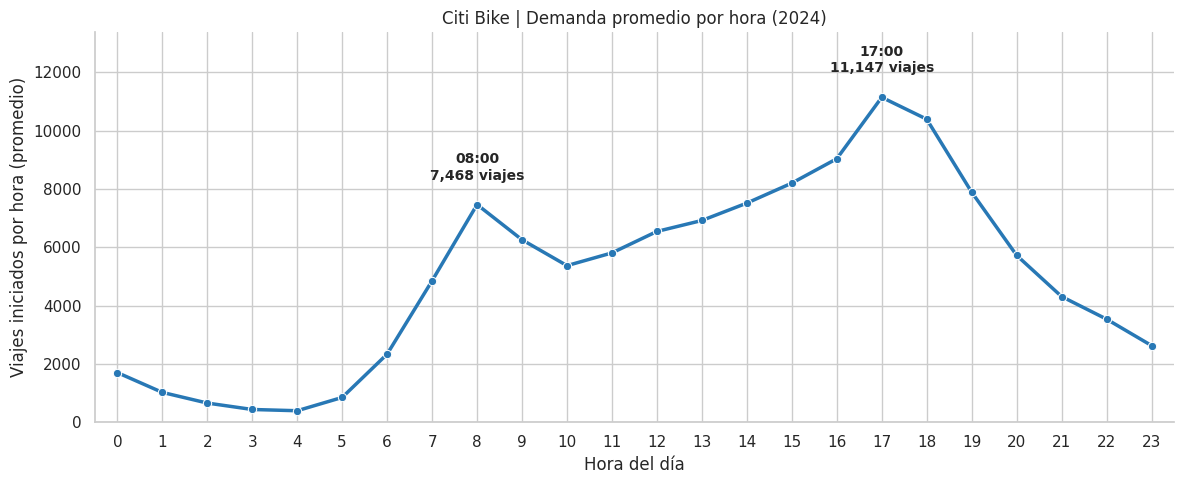

In [7]:
# Graficamos la demanda promedio de cada hora a lo largo del día
# Marcamos los dos picos que encontramos para que sean más fáciles de identificar

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=hourly_profile,
    x="hour",
    y="average_rides",
    marker="o",
    linewidth=2.5,
    color="#2878B5",
    ax=ax
)

# Señalamos los picos de la mañana y la tarde
for hour in [8, 17]:
    rides = hourly_profile.loc[
        hourly_profile["hour"] == hour, "average_rides"
    ].iloc[0]

    ax.annotate(
        f"{hour:02d}:00\n{rides:,.0f} viajes",
        xy=(hour, rides),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set(
    title="Citi Bike | Demanda promedio por hora (2024)",
    xlabel="Hora del día",
    ylabel="Viajes iniciados por hora (promedio)"
)

ax.set_xticks(range(0, 24))
ax.set_xlim(-0.5, 23.5)
# Dejamos algo de espacio arriba para que la etiqueta del pico no quede pegada al título
ax.set_ylim(0, hourly_profile["average_rides"].max() * 1.2)

sns.despine()
plt.tight_layout()
plt.show()

### H1 — Resultados e interpretación

La demanda de Citi Bike presenta un patrón horario con dos máximos
diferenciados:

- **08:00:** 7.468 viajes por hora, en promedio.
- **17:00:** 11.147 viajes por hora, en promedio.

El máximo vespertino supera al matutino aproximadamente un 49,3 %.

Además, la demanda de las 17:00 supera en un 121 % el promedio
horario general (5.044 viajes), mientras que la menor utilización
se registra a las 04:00, con apenas 395 viajes por hora.

La relación entre la demanda máxima y mínima alcanza 28,2 veces,
evidenciando una importante variación durante el día.

### Veredicto: Parcialmente apoyada

Los resultados confirman que existen franjas horarias de mayor
utilización, con dos picos compatibles con los horarios habituales
de desplazamiento laboral.

Sin embargo, los datos no permiten determinar el propósito real
de los viajes ni atribuir directamente estos patrones al commuting.

### Insight operativo

La demanda no se distribuye uniformemente durante el día.

Los horarios cercanos a las 08:00 y, especialmente, a las 17:00
representan períodos relevantes para la planificación operativa
del servicio.

Estos patrones podrían utilizarse para orientar decisiones sobre
disponibilidad de bicicletas, mantenimiento y redistribución,
aunque sería necesario incorporar información espacial para
definir acciones específicas por estación.

## 4. H2 — Días laborales vs. fines de semana

**Pregunta:** ¿Cómo cambia el patrón horario de demanda entre días laborales y fines de semana?

**Hipótesis:** Los días laborales presentan picos más marcados,
posiblemente asociados con desplazamientos al trabajo, mientras
que los fines de semana muestran una demanda más distribuida
durante el día.

Para evaluarla vamos a analizar:

- Demanda promedio por hora según el tipo de día.
- Horarios de mayor utilización en cada grupo.
- Diferencias en la distribución horaria.
- Concentración de la demanda en determinados horarios.

Compararemos promedios horarios y no totales acumulados, ya que
la cantidad de días laborales y fines de semana es diferente.

**Consideración:** clasificamos como días laborales de lunes a
viernes, sin excluir feriados.

In [8]:
# Separamos la demanda por tipo de día y hora
# Usamos mean para comparar promedios y no favorecer al grupo que tiene más días

h2_hourly = (
    analysis_df
    .groupby(["is_weekend", "hour"])["ride_count"]
    .mean()
    .unstack("is_weekend")
    .rename(columns={False: "weekday", True: "weekend"})
)

# Calculamos también qué porcentaje de la demanda diaria representa cada hora
# Así podemos comparar la forma de las curvas aunque un grupo tenga más viajes

h2_hourly_pct = (
    h2_hourly
    .div(h2_hourly.sum(axis=0), axis=1)
    * 100
)

print("DEMANDA PROMEDIO POR HORA:")
print(h2_hourly.round(1).to_string())

print("\nDISTRIBUCIÓN PORCENTUAL DE LA DEMANDA:")
print(h2_hourly_pct.round(2).to_string())

DEMANDA PROMEDIO POR HORA:
is_weekend  weekday  weekend
hour                        
0            1342.7   2611.6
1             705.1   1828.3
2             425.4   1251.0
3             282.0    831.0
4             333.0    551.8
5            1007.5    457.3
6            2906.1    904.6
7            6114.6   1679.2
8            9298.4   2857.6
9            6947.7   4527.3
10           5081.7   6107.2
11           5180.5   7394.9
12           5840.3   8322.8
13           6205.4   8727.3
14           6949.5   8951.0
15           7893.5   8984.0
16           9204.7   8625.5
17          12339.2   8143.4
18          11493.7   7632.8
19           8498.0   6370.2
20           6090.3   4808.1
21           4531.1   3764.1
22           3666.6   3212.3
23           2623.7   2649.9

DISTRIBUCIÓN PORCENTUAL DE LA DEMANDA:
is_weekend  weekday  weekend
hour                        
0              1.07     2.35
1              0.56     1.64
2              0.34     1.13
3              0.23     0.75
4    

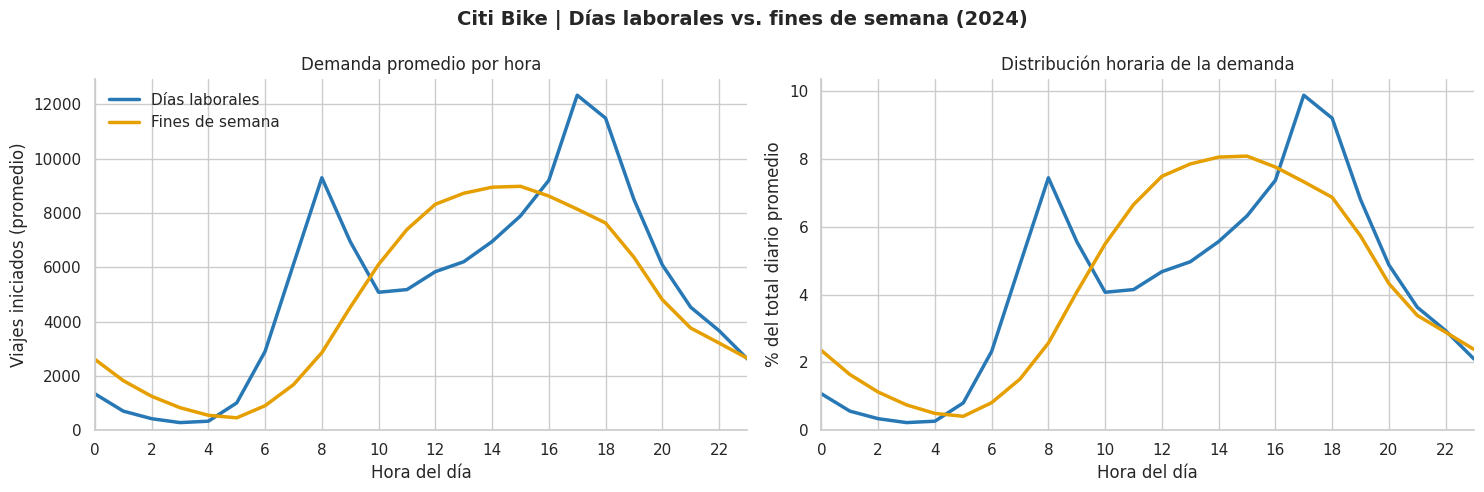

In [9]:
# Hacemos dos gráficos: uno para comparar la cantidad de viajes
# y otro para ver cómo se reparte la demanda dentro de cada tipo de día

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = {
    "weekday": "#2878B5",
    "weekend": "#E69F00"
}

labels = {
    "weekday": "Días laborales",
    "weekend": "Fines de semana"
}

for group in ["weekday", "weekend"]:

    # Primero comparamos la cantidad promedio de viajes por hora
    axes[0].plot(
        h2_hourly.index,
        h2_hourly[group],
        label=labels[group],
        color=colors[group],
        linewidth=2.5
    )

    # Ahora miramos qué porcentaje representa cada hora
    # Esto nos sirve para comparar patrones sin depender del volumen total
    axes[1].plot(
        h2_hourly_pct.index,
        h2_hourly_pct[group],
        color=colors[group],
        linewidth=2.5
    )

axes[0].set(
    title="Demanda promedio por hora",
    xlabel="Hora del día",
    ylabel="Viajes iniciados (promedio)"
)

axes[1].set(
    title="Distribución horaria de la demanda",
    xlabel="Hora del día",
    ylabel="% del total diario promedio"
)

# Dejamos los mismos horarios en ambos gráficos para facilitar la comparación
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlim(0, 23)
    ax.set_ylim(bottom=0)

axes[0].legend(frameon=False)

fig.suptitle(
    "Citi Bike | Días laborales vs. fines de semana (2024)",
    fontsize=14,
    fontweight="bold"
)

sns.despine()
plt.tight_layout()
plt.show()

### H2 — Resultados e interpretación

El análisis muestra diferencias claras entre el patrón horario
de los días laborales y el de los fines de semana.

En los **días laborales**, la demanda presenta dos picos bien
marcados:

- **08:00:** 9.298 viajes por hora, en promedio.
- **17:00:** 12.339 viajes por hora, en promedio.

Esto sugiere una mayor concentración de la demanda en horarios
compatibles con entradas y salidas de la jornada laboral.

En cambio, los **fines de semana** muestran una curva más gradual,
con niveles altos de demanda concentrados entre el mediodía y la
tarde. El máximo promedio ocurre a las **15:00**, con 8.984 viajes
por hora.

Además, entre las **12:00 y las 16:00**, los fines de semana
concentran aproximadamente **39,2 %** de su perfil diario,
mientras que los días laborales concentran **28,9 %** en ese
mismo rango horario.

También se observa que los fines de semana registran una mayor
actividad relativa durante la madrugada.

### Veredicto: Apoyada

La evidencia respalda la hipótesis de que el patrón de demanda
cambia según el tipo de día.

Los días laborales presentan picos horarios más marcados, mientras
que los fines de semana distribuyen la demanda de forma más
gradual y con mayor concentración durante las horas centrales
del día.

### Insight operativo

La demanda no solo cambia en cantidad, sino también en su
distribución horaria según el tipo de día.

Esto sugiere que la planificación operativa del sistema podría
beneficiarse de estrategias diferenciadas para días laborales y
fines de semana, especialmente en la asignación y redistribución
de bicicletas durante los horarios de mayor presión de demanda.

## 5. H3 — Member vs. Casual

**Pregunta:** ¿Los miembros y los usuarios ocasionales utilizan
Citi Bike de manera diferente?

**Hipótesis:** Los usuarios **member** presentan una demanda más
concentrada en días laborales y horarios compatibles con commuting,
mientras que los usuarios **casual** muestran una utilización más
asociada a momentos recreativos y fines de semana.

Para evaluarla vamos a analizar:

- Demanda promedio por hora según tipo de usuario.
- Distribución horaria de la demanda de cada segmento.
- Participación de cada segmento en el total de viajes.
- Diferencias entre días laborales y fines de semana, si aporta valor.

Primero vamos a comparar el perfil horario general de ambos grupos.

In [10]:
# Primero juntamos los viajes de classic y electric para cada tipo de usuario
# Así nos queda la demanda real de members y casuals en cada hora

h3_user_demand = (
    segmented_df
    .groupby(["datetime", "member_casual"])["ride_count"]
    .sum()
    .unstack(fill_value=0)
    .reindex(analysis_df["datetime"], fill_value=0)
)

# Calculamos el promedio para cada hora del día
# Incluimos todas las horas, incluso si algún segmento no tuvo viajes

h3_hourly_avg = (
    h3_user_demand
    .groupby(h3_user_demand.index.hour)
    .mean()
    .rename_axis("hour")
    [["member", "casual"]]
)

# Pasamos los promedios a porcentajes para comparar la forma de las curvas
h3_hourly_pct = (
    h3_hourly_avg
    .div(h3_hourly_avg.sum(axis=0), axis=1)
    * 100
)

# Comprobamos que no se perdió ningún viaje al reagrupar
assert (h3_user_demand.sum(axis=1).to_numpy()
        == analysis_df["ride_count"].to_numpy()).all()

print("DEMANDA PROMEDIO CORREGIDA:")
print(h3_hourly_avg.round(1).to_string())

print("\nDISTRIBUCIÓN PORCENTUAL:")
print(h3_hourly_pct.round(2).to_string())

print("\nValidación: todos los viajes coinciden.")

DEMANDA PROMEDIO CORREGIDA:
member_casual  member  casual
hour                         
0              1244.0   459.3
1               728.1   296.1
2               463.5   194.8
3               310.0   128.0
4               292.9   102.2
5               725.1   126.1
6              2067.4   269.9
7              4328.8   525.5
8              6671.0   797.2
9              5394.9   865.0
10             4374.7   998.4
11             4583.2  1226.6
12             5112.1  1433.7
13             5362.6  1559.4
14             5796.6  1721.6
15             6355.3  1848.0
16             7162.4  1877.7
17             9111.5  2035.4
18             8475.8  1920.8
19             6360.8  1532.6
20             4590.9  1135.0
21             3425.0   888.1
22             2747.1   790.4
23             1983.8   647.3

DISTRIBUCIÓN PORCENTUAL:
member_casual  member  casual
hour                         
0                1.27    1.96
1                0.75    1.27
2                0.47    0.83
3               

In [11]:
# Agregamos si cada hora corresponde a un día laboral o fin de semana
# Así podemos cruzar el tipo de usuario con el tipo de día

h3_day_type = h3_user_demand.join(
    analysis_df.set_index("datetime")["is_weekend"]
)

# Contamos cuántos días hay de cada tipo
# Es importante porque tenemos muchos más días laborales que fines de semana

days_by_type = analysis_df.groupby("is_weekend")["date"].nunique()

# Calculamos viajes por día, en promedio, para cada segmento
# Dividimos por la cantidad de días para hacer una comparación justa

h3_daily_avg = (
    h3_day_type
    .groupby("is_weekend")[["member", "casual"]]
    .sum()
    .div(days_by_type, axis=0)
    .rename(index={False: "weekday", True: "weekend"})
)

# Vemos qué porcentaje de los viajes corresponde a cada segmento
# dentro de cada tipo de día

h3_share = (
    h3_daily_avg
    .div(h3_daily_avg.sum(axis=1), axis=0)
    * 100
)

# Medimos cuánto cambia la demanda diaria al pasar al fin de semana

h3_weekend_change = (
    (h3_daily_avg.loc["weekend"] / h3_daily_avg.loc["weekday"] - 1)
    * 100
)

print("DÍAS POR GRUPO:")
print(days_by_type.to_string())

print("\nVIAJES PROMEDIO POR DÍA:")
print(h3_daily_avg.round(1).to_string())

print("\nPARTICIPACIÓN POR SEGMENTO (%):")
print(h3_share.round(2).to_string())

print("\nCAMBIO DE DEMANDA DIARIA EN FINES DE SEMANA (%):")
print(h3_weekend_change.round(2).to_string())

DÍAS POR GRUPO:
is_weekend
False    262
True     104

VIAJES PROMEDIO POR DÍA:
              member   casual
is_weekend                   
weekday     103921.6  21039.0
weekend      81907.9  29273.1

PARTICIPACIÓN POR SEGMENTO (%):
            member  casual
is_weekend                
weekday      83.16   16.84
weekend      73.67   26.33

CAMBIO DE DEMANDA DIARIA EN FINES DE SEMANA (%):
member   -21.18
casual    39.14


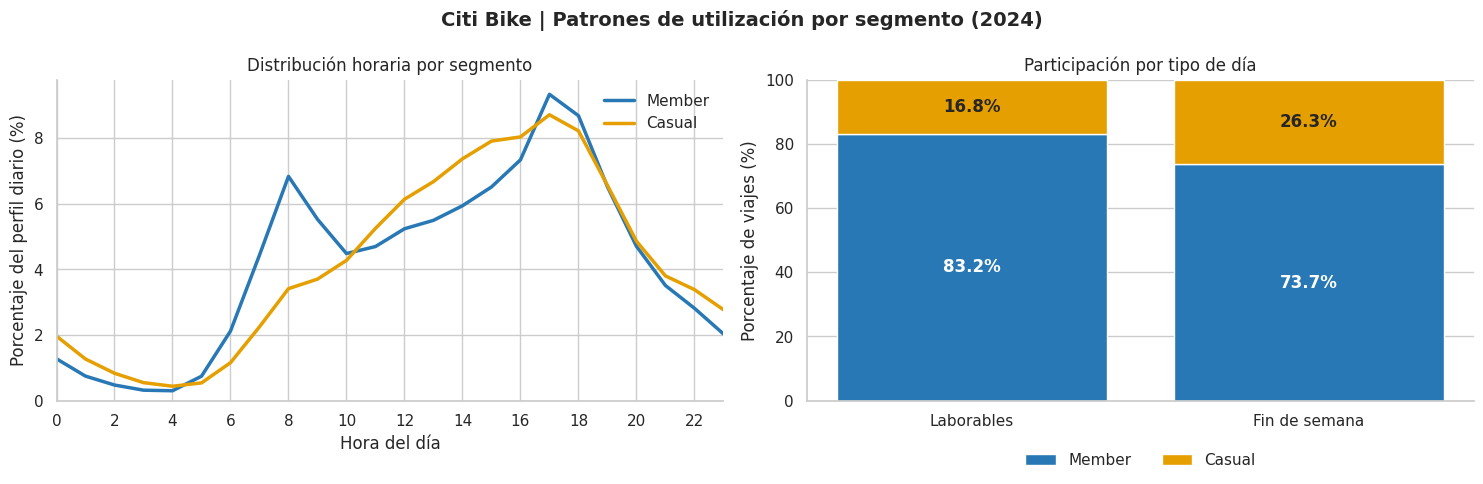

In [12]:
# Comparamos el perfil horario de ambos segmentos
# Usamos porcentajes porque los members tienen muchos más viajes en total

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = {
    "member": "#2878B5",
    "casual": "#E69F00"
}

for segment in ["member", "casual"]:
    axes[0].plot(
        h3_hourly_pct.index,
        h3_hourly_pct[segment],
        label=segment.capitalize(),
        color=colors[segment],
        linewidth=2.5
    )

axes[0].set(
    title="Distribución horaria por segmento",
    xlabel="Hora del día",
    ylabel="Porcentaje del perfil diario (%)"
)

axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlim(0, 23)
axes[0].set_ylim(bottom=0)
axes[0].legend(frameon=False)


# Ahora mostramos cómo cambia la participación de cada segmento
# Las barras suman 100%, así que podemos comparar la composición directamente

day_labels = ["Laborables", "Fin de semana"]
member_share = h3_share["member"].values
casual_share = h3_share["casual"].values

axes[1].bar(
    day_labels,
    member_share,
    color=colors["member"],
    label="Member"
)

axes[1].bar(
    day_labels,
    casual_share,
    bottom=member_share,
    color=colors["casual"],
    label="Casual"
)

# Agregamos los porcentajes dentro de las barras para facilitar la lectura
for i, (member, casual) in enumerate(zip(member_share, casual_share)):
    axes[1].text(i, member / 2, f"{member:.1f}%",
                 ha="center", va="center", color="white", fontweight="bold")

    axes[1].text(i, member + casual / 2, f"{casual:.1f}%",
                 ha="center", va="center", fontweight="bold")

axes[1].set(
    title="Participación por tipo de día",
    ylabel="Porcentaje de viajes (%)"
)

axes[1].set_ylim(0, 100)
# Movemos la leyenda debajo del gráfico para que no tape las barras
axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False
)
fig.suptitle(
    "Citi Bike | Patrones de utilización por segmento (2024)",
    fontsize=14,
    fontweight="bold"
)

sns.despine()
plt.tight_layout()
plt.show()

### H3 — Resultados e interpretación

Los resultados muestran diferencias importantes en los patrones
de utilización de Citi Bike según el tipo de usuario.

Los miembros representan el **80,7 % de los viajes anuales** y
presentan un pico matutino más pronunciado. A las 08:00 se
concentra el 6,83 % de su perfil horario, frente al 3,41 %
de los usuarios casuales.

Ambos segmentos alcanzan su demanda máxima a las 17:00, aunque
los casuales muestran una distribución más gradual durante
las horas centrales del día.

Las diferencias más importantes aparecen al comparar tipos
de día:

- **Member:** la demanda diaria disminuye un 21,18 % durante
  los fines de semana.
- **Casual:** la demanda diaria aumenta un 39,14 % durante
  los fines de semana.

Además, la participación de los usuarios casuales aumenta
del 16,84 % en días laborales al 26,33 % durante los fines
de semana, una diferencia de 9,49 puntos porcentuales.

### Veredicto: Apoyada

Los resultados respaldan la existencia de patrones de
utilización diferenciados entre miembros y usuarios ocasionales.

El comportamiento de los miembros es compatible con una mayor
utilización vinculada a desplazamientos habituales, mientras
que los usuarios casuales muestran patrones compatibles con
una mayor actividad recreativa.

Sin embargo, no contamos con información sobre el motivo de
cada viaje, por lo que estas interpretaciones no pueden
confirmarse directamente.

### Insight operativo

La segmentación de usuarios aporta información relevante para
la planificación de la demanda.

Los períodos laborales de mayor actividad de los miembros
y el aumento de utilización casual durante los fines de semana
sugieren necesidades operativas diferentes.

Estos resultados podrían orientar estrategias de disponibilidad,
redistribución de bicicletas y acciones comerciales diferenciadas
por segmento y tipo de día.

## 6. H4 — Condiciones climáticas

**Pregunta:** ¿Cómo se relacionan las condiciones meteorológicas
con la demanda horaria de Citi Bike?

**Hipótesis:** Las precipitaciones, las temperaturas extremas
y las mayores velocidades de viento están asociadas con una
menor utilización del servicio.

Para evaluarla vamos a analizar:

- Relación entre temperatura y demanda.
- Diferencias de demanda entre horas con y sin precipitación.
- Relación entre velocidad del viento y utilización.
- Posible influencia de la estacionalidad y los patrones horarios.

El objetivo es identificar asociaciones relevantes para
la planificación operativa, sin asumir relaciones causales.

In [13]:
# Elegimos las variables del clima que podrían tener relación con la demanda
# Por ahora no usamos weather_code porque es una clasificación, no una medida continua

weather_cols = [
    "temperature_2m",
    "apparent_temperature",
    "relative_humidity_2m",
    "precipitation",
    "snowfall",
    "wind_speed_10m"
]

# Miramos cómo se distribuyen los valores, especialmente los extremos
# Agregamos percentiles para no depender solamente de mínimos y máximos

weather_profile = (
    analysis_df[weather_cols]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)

print("PERFIL DE VARIABLES METEOROLÓGICAS:")
print(weather_profile.round(2).to_string())


# Contamos las horas con lluvia/nieve y las que no tuvieron precipitaciones
# Esto nos permite saber si tenemos suficientes casos para comparar

print("\nFRECUENCIA DE CONDICIONES CLIMÁTICAS:")

for col in ["has_precipitation", "has_snowfall"]:
    counts = analysis_df[col].value_counts(dropna=False)
    percentages = analysis_df[col].value_counts(
        normalize=True, dropna=False
    ) * 100

    print(f"\n{col}:")
    print(pd.DataFrame({
        "hours": counts,
        "percentage": percentages.round(2)
    }).to_string())

PERFIL DE VARIABLES METEOROLÓGICAS:
                       count   mean    std   min    5%   25%   50%   75%   95%    99%     max
temperature_2m        8783.0  13.07   9.86 -14.9  -3.0   5.2  13.4  21.3  28.2  32.00   36.30
apparent_temperature  8783.0  11.20  12.13 -19.1  -7.6   1.2  10.9  21.1  30.2  35.40   40.10
relative_humidity_2m  8783.0  68.86  19.32  15.0  36.0  54.0  70.0  86.0  97.0  99.00  100.00
precipitation         8783.0   0.15   0.77   0.0   0.0   0.0   0.0   0.0   0.7   3.40   17.30
snowfall              8783.0   0.01   0.07   0.0   0.0   0.0   0.0   0.0   0.0   0.07    2.38
wind_speed_10m        8783.0  12.40   6.46   0.0   4.1   7.6  11.2  16.1  24.5  31.92   57.30

FRECUENCIA DE CONDICIONES CLIMÁTICAS:

has_precipitation:
                   hours  percentage
has_precipitation                   
False               7480       85.16
True                1303       14.84

has_snowfall:
              hours  percentage
has_snowfall                   
False          8676 

In [14]:
# Separamos las horas con y sin precipitación para comparar la demanda
# Miramos promedio, mediana y desvío para ver si la diferencia es consistente

precip_comparison = (
    analysis_df
    .groupby("has_precipitation")["ride_count"]
    .agg(
        hours="size",
        average_rides="mean",
        median_rides="median",
        std_rides="std"
    )
    .rename(index={
        False: "Sin precipitación",
        True: "Con precipitación"
    })
)

# Calculamos cuánto cambia la demanda promedio cuando hay precipitación
# Lo expresamos como porcentaje respecto de las horas secas

dry_avg = precip_comparison.loc["Sin precipitación", "average_rides"]
wet_avg = precip_comparison.loc["Con precipitación", "average_rides"]

precip_diff_pct = (wet_avg / dry_avg - 1) * 100

print("DEMANDA SEGÚN PRECIPITACIÓN:")
print(precip_comparison.round(2).to_string())

print(f"\nDiferencia relativa: {precip_diff_pct:+.2f}%")

DEMANDA SEGÚN PRECIPITACIÓN:
                   hours  average_rides  median_rides  std_rides
has_precipitation                                               
Sin precipitación   7480        5299.05        4614.0    4175.59
Con precipitación   1303        3580.64        2419.0    3440.67

Diferencia relativa: -32.43%


In [15]:
# Armamos grupos con el mismo mes, hora y tipo de día
# La idea es comparar horas con y sin precipitación en contextos parecidos

groups = ["month_num", "hour", "is_weekend"]

precip_groups = (
    analysis_df
    .groupby(groups + ["has_precipitation"])["ride_count"]
    .agg(avg="mean", n="size")
    .reset_index()
)

# Separamos horas secas y húmedas para poder cruzarlas
dry = precip_groups[
    precip_groups["has_precipitation"] == False
].rename(columns={"avg": "dry_avg", "n": "dry_n"})

wet = precip_groups[
    precip_groups["has_precipitation"] == True
].rename(columns={"avg": "wet_avg", "n": "wet_n"})

# Nos quedamos con los grupos donde existen ambas condiciones
matched = dry.merge(wet, on=groups)

# Pedimos al menos 2 observaciones de cada condición
# Así evitamos basarnos en grupos con un solo dato
matched = matched[
    (matched["dry_n"] >= 2) & (matched["wet_n"] >= 2)
].copy()

if matched.empty:
    raise ValueError("No hay suficientes grupos comparables.")

# Usamos el tamaño del grupo más chico como peso
# Así los grupos con poca información no dominan la comparación
weights = np.minimum(matched["dry_n"], matched["wet_n"])

dry_adjusted = np.average(matched["dry_avg"], weights=weights)
wet_adjusted = np.average(matched["wet_avg"], weights=weights)

adjusted_diff = (wet_adjusted / dry_adjusted - 1) * 100

# Revisamos cuántas horas con precipitación quedaron representadas
wet_coverage = matched["wet_n"].sum() / analysis_df["has_precipitation"].sum() * 100

print(f"Grupos comparables: {len(matched)}")
print(f"Cobertura de horas con precipitación: {wet_coverage:.1f}%")
print(f"Demanda seca comparable: {dry_adjusted:,.1f}")
print(f"Demanda húmeda comparable: {wet_adjusted:,.1f}")
print(f"Diferencia estratificada: {adjusted_diff:+.2f}%")
print(f"Diferencia bruta original: {precip_diff_pct:+.2f}%")

Grupos comparables: 343
Cobertura de horas con precipitación: 90.0%
Demanda seca comparable: 5,262.2
Demanda húmeda comparable: 3,554.3
Diferencia estratificada: -32.46%
Diferencia bruta original: -32.43%


In [16]:
# Dividimos las temperaturas en rangos de 5 grados
# Así podemos ver si la demanda cambia de forma gradual o tiene algún punto óptimo

temp_df = analysis_df.copy()

temp_df["temp_bin"] = pd.cut(
    temp_df["temperature_2m"],
    bins=np.arange(-15, 41, 5),
    right=False
)

# Calculamos la demanda típica de cada rango
# También contamos las horas para saber qué tan representativo es cada grupo

temp_summary = (
    temp_df
    .groupby("temp_bin", observed=True)["ride_count"]
    .agg(
        hours="size",
        average_rides="mean",
        median_rides="median"
    )
    .reset_index()
)

# Vemos qué proporción del año representa cada intervalo
temp_summary["pct_hours"] = (
    temp_summary["hours"] / len(temp_df) * 100
)

print("DEMANDA SEGÚN TEMPERATURA:")
print(temp_summary.round(2).to_string(index=False))

DEMANDA SEGÚN TEMPERATURA:
  temp_bin  hours  average_rides  median_rides  pct_hours
[-15, -10)     19        1035.00         877.0       0.22
 [-10, -5)    175        1194.59         725.0       1.99
   [-5, 0)    732        2036.84        1490.0       8.33
    [0, 5)   1216        2868.40        2464.0      13.84
   [5, 10)   1434        3478.27        3119.0      16.33
  [10, 15)   1233        4922.84        4730.0      14.04
  [15, 20)   1396        5267.13        4757.5      15.89
  [20, 25)   1486        6968.86        6852.5      16.92
  [25, 30)    858        9384.79        9294.5       9.77
  [30, 35)    221        9691.81        9031.0       2.52
  [35, 40)     13       10341.38        9947.0       0.15


In [17]:
# Primero nos quedamos con las horas sin precipitación
# Así la lluvia no nos mezcla tanto los resultados

temp_dry = analysis_df.loc[
    ~analysis_df["has_precipitation"],
    ["temperature_2m", "ride_count", "month_num", "hour", "is_weekend"]
].copy()

groups = ["month_num", "hour", "is_weekend"]

# Dejamos grupos con al menos 5 observaciones
# No queremos comparar temperaturas usando grupos demasiado chicos
group_sizes = temp_dry.groupby(groups)["ride_count"].transform("size")
temp_dry = temp_dry[group_sizes >= 5].copy()

# Calculamos el promedio de temperatura y demanda de cada grupo
# Después vemos cuánto se aleja cada observación de ese promedio

group_means = (
    temp_dry
    .groupby(groups)[["temperature_2m", "ride_count"]]
    .transform("mean")
)

temp_dry["temp_anomaly"] = (
    temp_dry["temperature_2m"] - group_means["temperature_2m"]
)

temp_dry["rides_anomaly"] = (
    temp_dry["ride_count"] - group_means["ride_count"]
)

# Comparamos la correlación original con la correlación de esas diferencias
# Pearson nos sirve para medir la asociación lineal

raw_corr = temp_dry["temperature_2m"].corr(temp_dry["ride_count"])
adjusted_corr = temp_dry["temp_anomaly"].corr(temp_dry["rides_anomaly"])

print(f"Observaciones utilizadas: {len(temp_dry):,}")
print(f"Cobertura de horas secas: {len(temp_dry) / (~analysis_df['has_precipitation']).sum() * 100:.1f}%")
print(f"Correlación original: {raw_corr:.3f}")
print(f"Correlación ajustada por factores temporales: {adjusted_corr:.3f}")

Observaciones utilizadas: 7,480
Cobertura de horas secas: 100.0%
Correlación original: 0.544
Correlación ajustada por factores temporales: 0.396


In [18]:
# Nos quedamos con las horas secas para que la lluvia no influya tanto
# Dividimos el viento en rangos para ver cómo cambia la demanda

wind_df = analysis_df[~analysis_df["has_precipitation"]].copy()

wind_df["wind_range"] = pd.cut(
    wind_df["wind_speed_10m"],
    bins=[0, 5, 10, 15, 20, 25, 30, np.inf],
    right=False
)

# Calculamos cuántas horas hay por rango y su demanda promedio
# Esto también nos ayuda a detectar rangos con pocos registros

wind_summary = (
    wind_df
    .groupby("wind_range", observed=True)["ride_count"]
    .agg(hours="size", average_rides="mean", median_rides="median")
    .reset_index()
)

print("DEMANDA SEGÚN VELOCIDAD DEL VIENTO:")
print(wind_summary.round(2).to_string(index=False))


# Comparamos las horas contra otras del mismo mes, horario y tipo de día
# Restamos los promedios de cada grupo para reducir la influencia temporal

groups = ["month_num", "hour", "is_weekend"]

group_means = (
    wind_df
    .groupby(groups)[["wind_speed_10m", "ride_count"]]
    .transform("mean")
)

wind_df["wind_anomaly"] = (
    wind_df["wind_speed_10m"] - group_means["wind_speed_10m"]
)

wind_df["rides_anomaly"] = (
    wind_df["ride_count"] - group_means["ride_count"]
)

# Calculamos las correlaciones antes y después del ajuste
raw_corr_wind = wind_df["wind_speed_10m"].corr(wind_df["ride_count"])
adjusted_corr_wind = wind_df["wind_anomaly"].corr(wind_df["rides_anomaly"])

print(f"\nObservaciones utilizadas: {len(wind_df):,}")
print(f"Correlación original: {raw_corr_wind:.3f}")
print(f"Correlación ajustada: {adjusted_corr_wind:.3f}")

DEMANDA SEGÚN VELOCIDAD DEL VIENTO:
  wind_range  hours  average_rides  median_rides
  [0.0, 5.0)    610        4492.64        3729.5
 [5.0, 10.0)   2690        4200.85        3366.0
[10.0, 15.0)   2103        5539.47        4861.0
[15.0, 20.0)   1274        6782.79        6546.5
[20.0, 25.0)    550        6653.11        6423.0
[25.0, 30.0)    183        6236.20        5442.0
 [30.0, inf)     70        7212.61        7436.0

Observaciones utilizadas: 7,480
Correlación original: 0.220
Correlación ajustada: -0.037


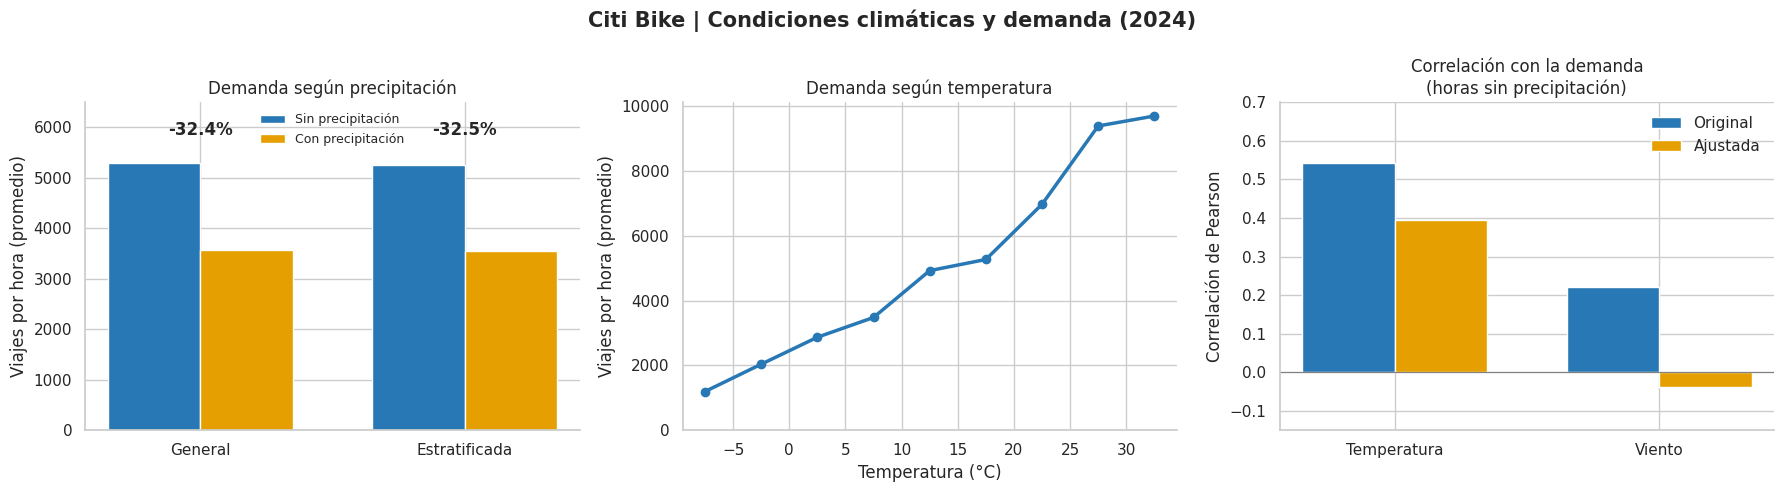

In [19]:
# Juntamos los resultados del clima en una sola figura
# La idea es mostrar lo importante sin llenar el notebook de gráficos

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

blue = "#2878B5"
orange = "#E69F00"

# 1. Precipitación: comparamos los promedios generales y estratificados
x = np.arange(2)
width = 0.35

axes[0].bar(
    x - width/2, [dry_avg, dry_adjusted],
    width, label="Sin precipitación", color=blue
)
axes[0].bar(
    x + width/2, [wet_avg, wet_adjusted],
    width, label="Con precipitación", color=orange
)

axes[0].set(
    title="Demanda según precipitación",
    ylabel="Viajes por hora (promedio)"
)
axes[0].set_xticks(x, ["General", "Estratificada"])
axes[0].set_ylim(0, 6500)
axes[0].legend(frameon=False, fontsize=9)

for i, diff in enumerate([precip_diff_pct, adjusted_diff]):
    axes[0].text(i, 5850, f"{diff:.1f}%",
                 ha="center", fontweight="bold")


# 2. Temperatura: dejamos afuera los rangos con menos de 100 horas
# Son muy pocos datos y podrían dar una idea equivocada

temp_plot = temp_summary[temp_summary["hours"] >= 100].copy()
temp_plot["temp_center"] = [
    interval.mid for interval in temp_plot["temp_bin"]
]

axes[1].plot(
    temp_plot["temp_center"],
    temp_plot["average_rides"],
    marker="o", linewidth=2.5, color=blue
)

axes[1].set(
    title="Demanda según temperatura",
    xlabel="Temperatura (°C)",
    ylabel="Viajes por hora (promedio)"
)
axes[1].set_ylim(bottom=0)


# 3. Comparamos las correlaciones antes y después del ajuste
# Acá se ve especialmente bien cómo cambia el resultado del viento

variables = ["Temperatura", "Viento"]
raw_values = [raw_corr, raw_corr_wind]
adjusted_values = [adjusted_corr, adjusted_corr_wind]

x = np.arange(len(variables))

axes[2].bar(
    x - width/2, raw_values, width,
    label="Original", color=blue
)
axes[2].bar(
    x + width/2, adjusted_values, width,
    label="Ajustada", color=orange
)

axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set(
    title="Correlación con la demanda\n(horas sin precipitación)",
    ylabel="Correlación de Pearson"
)
axes[2].set_xticks(x, variables)
axes[2].set_ylim(-0.15, 0.7)
axes[2].legend(frameon=False)

fig.suptitle(
    "Citi Bike | Condiciones climáticas y demanda (2024)",
    fontsize=15, fontweight="bold"
)

sns.despine()
plt.tight_layout()
plt.show()


### H4 — Resultados e interpretación

El análisis identifica asociaciones diferentes entre las condiciones
meteorológicas y la demanda horaria de Citi Bike.

**Precipitación**

Las horas con precipitación registran una demanda promedio un
32,43 % menor que las horas secas.

Al comparar observaciones del mismo mes, hora y tipo de día, la
diferencia se mantiene en **−32,46 %**, utilizando 343 grupos
comparables que representan el 90 % de las horas con precipitación.

Esto refuerza la evidencia de una asociación negativa entre
precipitación y utilización del servicio.

**Temperatura**

La demanda aumenta progresivamente entre los rangos de
temperatura analizados.

La correlación de Pearson es de **+0,544** en horas secas y
disminuye a **+0,396** después del ajuste por mes, hora y
tipo de día.

Esto indica que parte de la asociación está relacionada con
factores temporales, aunque se mantiene una relación positiva.

No encontramos evidencia descriptiva de una disminución de
demanda por temperaturas elevadas, pero las observaciones
por encima de 35 °C son demasiado escasas para obtener
conclusiones sólidas sobre el calor extremo.

**Velocidad del viento**

La correlación inicial es positiva y débil (**+0,220**),
pero disminuye a **−0,037** después del ajuste temporal.

Por lo tanto, no encontramos evidencia de una asociación
lineal negativa relevante entre velocidad del viento
y demanda bajo las condiciones analizadas.

Esto no descarta posibles relaciones no lineales ni efectos
específicos de vientos extremos.

### Veredicto: Parcialmente apoyada

La evidencia respalda la asociación entre precipitaciones y
menor utilización, así como entre temperaturas bajas y
menor demanda.

Sin embargo, no encontramos evidencia suficiente para respaldar
una disminución por temperaturas elevadas o una asociación
lineal negativa relevante con el viento.

Las relaciones identificadas son observacionales y no deben
interpretarse como efectos causales.

### Insight operativo

Las condiciones meteorológicas, especialmente la precipitación
y la temperatura, aportan información relevante para anticipar
variaciones en la demanda.

La planificación operativa podría incorporar pronósticos de
precipitación y temperatura para ajustar sus estimaciones de
utilización y evaluar necesidades de disponibilidad de bicicletas.

Estos resultados también justifican incorporar variables
meteorológicas en un futuro modelo predictivo de demanda horaria.

Sin embargo, su utilidad predictiva deberá comprobarse mediante
validación temporal y comparación con modelos que utilicen
únicamente variables de calendario.


## 7. H5 — Estacionalidad de la demanda

**Pregunta:** ¿Cómo cambia la demanda de Citi Bike según el mes
y la estación del año?

**Hipótesis:** La demanda aumenta durante los meses templados
y cálidos, mientras que disminuye durante los períodos con
condiciones climáticas menos favorables.

Para evaluarla vamos a analizar:

- Evolución mensual de los viajes.
- Demanda diaria promedio por mes.
- Diferencias entre estaciones del año.
- Relación descriptiva entre temperatura y demanda estacional.

Buscamos identificar los períodos de mayor y menor utilización
y comprender cómo esta información puede ayudar a la
planificación operativa.

**Limitación:** el análisis cubre solamente 2024. Por lo tanto,
podemos identificar patrones dentro de ese año, pero no confirmar
que se repitan de forma consistente en otros años.

In [20]:
# Primero juntamos los viajes de cada día
# Así no mezclamos el total mensual con la cantidad de horas o días que tiene cada mes

daily_demand = (
    analysis_df
    .assign(date=analysis_df["datetime"].dt.normalize())
    .groupby("date", as_index=False)["ride_count"]
    .sum()
    .rename(columns={"ride_count": "daily_rides"})
)

daily_demand["month_num"] = daily_demand["date"].dt.month

# Ahora agrupamos por mes y sacamos el total, promedio y mediana de viajes diarios
# El promedio diario nos sirve más que el total para comparar meses entre sí

monthly_summary = (
    daily_demand
    .groupby("month_num")["daily_rides"]
    .agg(
        days="size",
        total_rides="sum",
        avg_daily_rides="mean",
        median_daily_rides="median"
    )
    .reset_index()
)

# Ponemos los nombres de los meses para que la tabla sea más fácil de leer

month_names = {
    1: "Enero", 2: "Febrero", 3: "Marzo",
    4: "Abril", 5: "Mayo", 6: "Junio",
    7: "Julio", 8: "Agosto", 9: "Septiembre",
    10: "Octubre", 11: "Noviembre", 12: "Diciembre"
}

monthly_summary["month"] = monthly_summary["month_num"].map(month_names)

# Revisamos que tengamos todos los días del año y no hayamos perdido viajes
# 2024 fue bisiesto, así que deberían aparecer 366 días

assert len(daily_demand) == 366
assert monthly_summary["total_rides"].sum() == 44_302_480

print("DEMANDA MENSUAL:")
print(
    monthly_summary[
        ["month", "days", "total_rides", "avg_daily_rides", "median_daily_rides"]
    ]
    .round(1)
    .to_string(index=False)
)

print("\nValidación: cobertura anual y viajes correctos.")

DEMANDA MENSUAL:
     month  days  total_rides  avg_daily_rides  median_daily_rides
     Enero    31      1887908          60900.3             65912.0
   Febrero    29      2121506          73155.4             75489.0
     Marzo    31      2663416          85916.6             90816.0
     Abril    30      3216957         107231.9            111350.0
      Mayo    31      4135049         133388.7            140208.0
     Junio    30      4782935         159431.2            164293.5
     Julio    31      4722952         152353.3            152016.0
    Agosto    31      4603942         148514.3            154607.0
Septiembre    30      4997288         166576.3            172948.0
   Octubre    31      5150717         166152.2            168671.0
 Noviembre    30      3708910         123630.3            132525.0
 Diciembre    31      2310900          74545.2             80604.0

Validación: cobertura anual y viajes correctos.


In [21]:
# Recuperamos la estación de cada día usando lo que ya teníamos en analysis_df
# Así no tenemos que volver a definir qué meses pertenecen a cada estación

season_by_day = (
    analysis_df
    .assign(date=analysis_df["datetime"].dt.normalize())
    .groupby("date")["season"]
    .first()
)

daily_demand["season"] = daily_demand["date"].map(season_by_day)

# Ahora agrupamos los viajes diarios por estación
# Calculamos total, promedio y mediana para poder comparar bien

season_summary = (
    daily_demand
    .groupby("season")["daily_rides"]
    .agg(
        days="size",
        total_rides="sum",
        avg_daily_rides="mean",
        median_daily_rides="median"
    )
    .reindex(["Winter", "Spring", "Summer", "Autumn"])
    .reset_index()
)

# Comprobamos que al agrupar no perdimos ningún viaje
assert daily_demand["season"].notna().all()
assert season_summary["total_rides"].sum() == 44_302_480

print("DEMANDA POR ESTACIÓN:")
print(season_summary.round(1).to_string(index=False))

# Buscamos la estación con mayor y menor demanda diaria
highest = season_summary.loc[season_summary["avg_daily_rides"].idxmax()]
lowest = season_summary.loc[season_summary["avg_daily_rides"].idxmin()]

difference_pct = (
    highest["avg_daily_rides"] / lowest["avg_daily_rides"] - 1
) * 100

print(f"\nEstación con mayor demanda: {highest['season']}")
print(f"Estación con menor demanda: {lowest['season']}")
print(f"Diferencia relativa: +{difference_pct:.1f}%")

DEMANDA POR ESTACIÓN:
season  days  total_rides  avg_daily_rides  median_daily_rides
Winter    91      6320314          69454.0             72462.0
Spring    92     10015422         108863.3            111793.0
Summer    92     14109829         153367.7            157283.0
Autumn    91     13856915         152273.8            164213.0

Estación con mayor demanda: Summer
Estación con menor demanda: Winter
Diferencia relativa: +120.8%


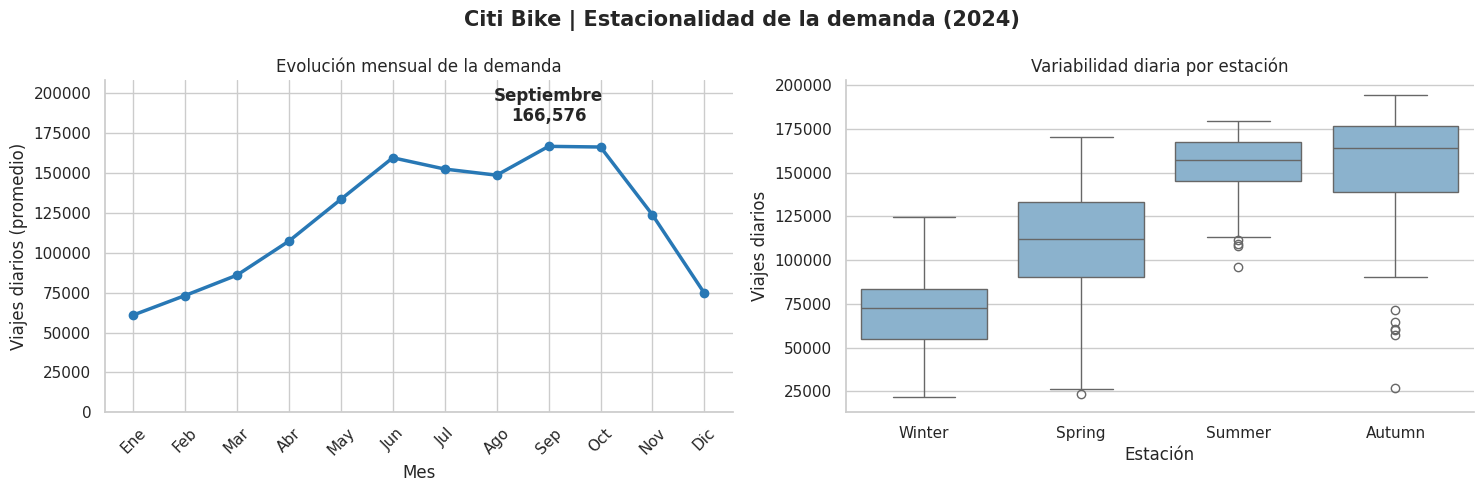

In [22]:
# Hacemos dos gráficos: uno para ver cómo evoluciona la demanda durante el año
# y otro para comparar qué tanto varían los viajes diarios dentro de cada estación

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Primero mostramos los viajes diarios promedio de cada mes
axes[0].plot(
    monthly_summary["month_num"],
    monthly_summary["avg_daily_rides"],
    marker="o",
    linewidth=2.5,
    color="#2878B5"
)

axes[0].set(
    title="Evolución mensual de la demanda",
    xlabel="Mes",
    ylabel="Viajes diarios (promedio)"
)

axes[0].set_xticks(
    monthly_summary["month_num"],
    monthly_summary["month"].str[:3],
    rotation=45
)
axes[0].set_ylim(bottom=0)

# Marcamos el mes con mayor demanda diaria promedio
peak_month = monthly_summary.loc[
    monthly_summary["avg_daily_rides"].idxmax()
]

axes[0].annotate(
    f"{peak_month['month']}\n{peak_month['avg_daily_rides']:,.0f}",
    xy=(peak_month["month_num"], peak_month["avg_daily_rides"]),
    xytext=(0, 18),
    textcoords="offset points",
    ha="center",
    fontweight="bold"
)


# El boxplot nos deja ver la mediana, dispersión y días atípicos
# Sirve especialmente para entender por qué otoño y verano tienen promedios parecidos

season_order = ["Winter", "Spring", "Summer", "Autumn"]

sns.boxplot(
    data=daily_demand,
    x="season",
    y="daily_rides",
    order=season_order,
    color="#80B4D8",
    ax=axes[1]
)

axes[1].set(
    title="Variabilidad diaria por estación",
    xlabel="Estación",
    ylabel="Viajes diarios"
)

fig.suptitle(
    "Citi Bike | Estacionalidad de la demanda (2024)",
    fontsize=15,
    fontweight="bold"
)

# Dejamos algo de espacio arriba para que el valor de septiembre no se superponga con el título
axes[0].set_ylim(0, monthly_summary["avg_daily_rides"].max() * 1.25)

sns.despine()
plt.tight_layout()
plt.show()

### H5 — Resultados e interpretación

La demanda de Citi Bike presenta variaciones importantes a lo
largo de 2024, con una utilización considerablemente menor
durante los meses fríos.

**Evolución mensual**

La demanda diaria promedio aumenta desde enero (60.900 viajes)
hasta junio (159.431 viajes), con una leve disminución durante
julio y agosto.

Los niveles más altos aparecen en septiembre y octubre, con
166.576 y 166.152 viajes diarios promedio, respectivamente.

Septiembre registra aproximadamente 2,74 veces la demanda
diaria de enero.

**Comparación estacional**

El verano presenta la mayor demanda diaria promedio, con
153.368 viajes, seguido muy de cerca por otoño, con 152.274.

En cambio, invierno registra apenas 69.454 viajes diarios.

La demanda promedio de verano es un **120,8 % superior** a
la de invierno.

**Variabilidad diaria**

El análisis mediante boxplots muestra diferencias en la
distribución de la demanda entre estaciones.

Aunque verano presenta un promedio ligeramente superior,
otoño tiene una mediana diaria más elevada (164.213 frente
a 157.283 viajes) y una mayor dispersión.

Esto indica que los promedios estacionales pueden ocultar
diferencias importantes entre los días que componen cada período.

### Veredicto: Apoyada

Los resultados respaldan la hipótesis de que la demanda
presenta variaciones estacionales, con mayor utilización
durante los períodos cálidos y menor actividad en invierno.

Sin embargo, la relación no es completamente uniforme:
septiembre y octubre superan individualmente a los meses
de verano en demanda diaria promedio.

Además, al analizar únicamente 2024, no podemos confirmar
que este patrón se repita en otros años ni atribuir las
diferencias exclusivamente a las condiciones meteorológicas.

### Insight operativo

La estacionalidad representa una dimensión importante para
la planificación de capacidad del sistema.

La mayor demanda registrada entre junio y octubre sugiere
que estos meses podrían requerir mayores niveles de
disponibilidad y atención operativa.

En cambio, los meses de menor utilización podrían ofrecer
oportunidades para planificar ciertas tareas de mantenimiento,
siempre considerando las necesidades específicas de cada estación.

Estos resultados también justifican incorporar variables
de calendario y estacionalidad en el futuro modelo predictivo,
evaluando su aporte mediante validación temporal.

## 8. H6 — Concentración de viajes por estación

**Pregunta:** ¿Una proporción pequeña de estaciones concentra
una parte importante de los viajes iniciados?

**Hipótesis:** La demanda no se distribuye uniformemente entre
las estaciones de Citi Bike. Se espera que una proporción
relativamente pequeña concentre gran parte de los viajes.

Para evaluarla vamos a analizar:

- Cantidad de viajes iniciados por estación.
- Participación de las estaciones con mayor actividad.
- Porcentaje de viajes concentrado en el Top 10 % y 20 %.
- Cantidad de estaciones necesarias para acumular el 50 % de los viajes.
- Distribución acumulada mediante una curva de Lorenz.

**Alcance:** analizamos únicamente viajes iniciados en cada
estación durante 2024, utilizando `start_station_id` como
identificador.

No incluimos llegadas ni interpretamos directamente estos
resultados como disponibilidad o déficit de bicicletas.

In [23]:
# Primero revisamos si los IDs repetidos tienen nombres diferentes
# Puede que una misma estación haya cambiado de nombre durante el año

station_diagnostics = (
    stations_df
    .groupby("start_station_id")
    .agg(
        records=("start_station_name", "size"),
        unique_names=("start_station_name", "nunique"),
        total_rides=("ride_count", "sum")
    )
    .reset_index()
)

# Contamos cuántos IDs aparecen más de una vez
# Y cuántos están asociados a distintos nombres

print("IDs con múltiples registros:",
      (station_diagnostics["records"] > 1).sum())

print("IDs con múltiples nombres:",
      (station_diagnostics["unique_names"] > 1).sum())

# Revisamos si también existen combinaciones idénticas de ID y nombre
print("Pares ID + nombre duplicados:",
      stations_df.duplicated(
          subset=["start_station_id", "start_station_name"]
      ).sum())

# Miramos algunos casos concretos para entender de dónde viene el problema
# Elegimos los IDs que aparecen con más nombres diferentes

sample_ids = (
    station_diagnostics
    .sort_values("unique_names", ascending=False)
    .head(5)["start_station_id"]
)

print("\nEJEMPLOS DE IDs REPETIDOS:")
print(
    stations_df[
        stations_df["start_station_id"].isin(sample_ids)
    ]
    .sort_values(["start_station_id", "ride_count"])
    .to_string(index=False)
)

IDs con múltiples registros: 1743
IDs con múltiples nombres: 12
Pares ID + nombre duplicados: 1741

EJEMPLOS DE IDs REPETIDOS:
start_station_id          start_station_name  ride_count
         4968.03        Bridge St & Water St           6
         4968.03        Bridge St & Front St        6078
         4968.03        Bridge St & Water St       26796
         5772.05   Morton St & Washington St          33
         5772.05    Morton St & Greenwich St       22102
         5772.05   Morton St & Washington St       30887
         7253.04 Central Park West & W 76 St          25
         7253.04    Central Park W & W 76 St         664
         7253.04 Central Park West & W 76 St       47756
         7304.08 W 82 St & Central Park West          15
         7304.08    W 82 St & Central Park W         632
         7304.08 W 82 St & Central Park West       42117
         7354.01 Central Park West & W 85 St          22
         7354.01    Central Park W & W 85 St         794
         7354.01 C

In [24]:
# Hay varios registros para una misma estación, así que los juntamos por ID
# Sumamos sus viajes para no perder información al consolidarlos

stations_h6 = (
    stations_df
    .groupby("start_station_id", as_index=False)["ride_count"]
    .sum()
)

# Ordenamos las estaciones de mayor a menor cantidad de salidas
stations_h6 = (
    stations_h6
    .sort_values("ride_count", ascending=False)
    .reset_index(drop=True)
)

# Comprobamos que conservamos todos los viajes
# Y que ahora sí tenemos una sola fila por identificador

assert stations_h6["ride_count"].sum() == stations_df["ride_count"].sum()
assert stations_h6["start_station_id"].is_unique

print("ESTACIONES CONSOLIDADAS:")
print("Registros originales:", len(stations_df))
print("IDs únicos:", len(stations_h6))
print("Viajes representados:", f"{stations_h6['ride_count'].sum():,}")

print("\nTOP 10 ESTACIONES POR VIAJES INICIADOS:")
print(stations_h6.head(10).to_string(index=False))

print("\nValidaciones correctas.")

ESTACIONES CONSOLIDADAS:
Registros originales: 4131
IDs únicos: 2378
Viajes representados: 44,272,646

TOP 10 ESTACIONES POR VIAJES INICIADOS:
start_station_id  ride_count
         6140.05      163490
         6450.05      140697
         5905.14      140016
         5329.03      135965
         5788.13      134509
         6331.01      128283
         5905.12      128196
         6726.01      127605
         6173.08      120923
         6948.10      116990

Validaciones correctas.


In [25]:
# Calculamos cuántas estaciones entran en el top 10% y 20%
# Redondeamos hacia arriba porque no podemos tomar una parte de una estación

total_stations = len(stations_h6)
total_rides = stations_h6["ride_count"].sum()

top_10_n = int(np.ceil(total_stations * 0.10))
top_20_n = int(np.ceil(total_stations * 0.20))

# Sumamos los viajes de las estaciones que más se utilizan
# Así vemos qué parte de la demanda concentran esos grupos

top_10_share = (
    stations_h6.head(top_10_n)["ride_count"].sum()
    / total_rides * 100
)

top_20_share = (
    stations_h6.head(top_20_n)["ride_count"].sum()
    / total_rides * 100
)

# Vamos acumulando los viajes desde la estación más utilizada
# Buscamos cuántas necesitamos para llegar al 50% de toda la demanda

stations_h6["cumulative_share"] = (
    stations_h6["ride_count"].cumsum() / total_rides
)

stations_for_50 = int(
    (stations_h6["cumulative_share"] < 0.50).sum() + 1
)

stations_for_50_pct = stations_for_50 / total_stations * 100

print("CONCENTRACIÓN DE VIAJES POR ESTACIÓN")
print(f"Total de IDs: {total_stations:,}")

print(f"\nTop 10% ({top_10_n} estaciones): {top_10_share:.2f}% de viajes")
print(f"Top 20% ({top_20_n} estaciones): {top_20_share:.2f}% de viajes")

print(f"\nEstaciones necesarias para el 50% de viajes: {stations_for_50}")
print(f"Porcentaje de estaciones necesario: {stations_for_50_pct:.2f}%")

CONCENTRACIÓN DE VIAJES POR ESTACIÓN
Total de IDs: 2,378

Top 10% (238 estaciones): 39.67% de viajes
Top 20% (476 estaciones): 62.44% de viajes

Estaciones necesarias para el 50% de viajes: 335
Porcentaje de estaciones necesario: 14.09%


Coeficiente de Gini: 0.599


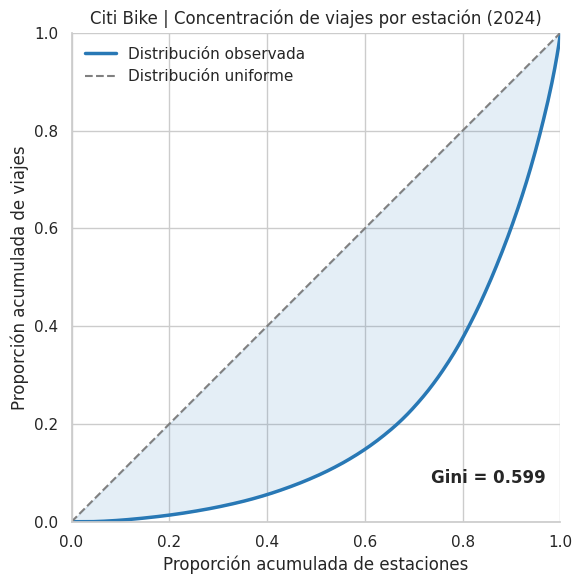

In [26]:
# Ordenamos las estaciones de menor a mayor cantidad de viajes
# Para la curva de Lorenz necesitamos empezar por las menos utilizadas

station_rides = np.sort(stations_h6["ride_count"].to_numpy())

# Calculamos qué porcentaje de estaciones y viajes vamos acumulando
# Agregamos el cero para que la curva arranque desde el origen

lorenz_x = np.arange(len(station_rides) + 1) / len(station_rides)

lorenz_y = np.insert(
    np.cumsum(station_rides) / station_rides.sum(),
    0, 0
)

# El Gini mide el área entre la diagonal y nuestra curva
# Usamos trapezoid para calcular el área debajo de la curva

gini = 1 - 2 * np.trapezoid(lorenz_y, lorenz_x)

print(f"Coeficiente de Gini: {gini:.3f}")

# Ahora graficamos la distribución real contra una distribución uniforme

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    lorenz_x, lorenz_y,
    color="#2878B5",
    linewidth=2.5,
    label="Distribución observada"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Distribución uniforme"
)

# Sombreamos la diferencia para mostrar visualmente la desigualdad
ax.fill_between(
    lorenz_x, lorenz_y, lorenz_x,
    color="#2878B5",
    alpha=0.12
)

ax.set(
    title="Citi Bike | Concentración de viajes por estación (2024)",
    xlabel="Proporción acumulada de estaciones",
    ylabel="Proporción acumulada de viajes"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal", adjustable="box")

ax.legend(frameon=False, loc="upper left")

ax.text(
    0.97, 0.08,
    f"Gini = {gini:.3f}",
    transform=ax.transAxes,
    ha="right",
    fontsize=12,
    fontweight="bold"
)

sns.despine()
plt.tight_layout()
plt.show()


### H6 — Resultados e interpretación

El análisis de 44.272.646 viajes con estación de origen identificada
muestra una concentración considerable de la demanda de Citi Bike.

**Concentración de viajes**

Después de consolidar los registros por identificador de estación,
se obtuvieron 2.378 IDs únicos.

Los resultados muestran que:

- El 10 % de los identificadores (238) concentra el 39,67 % de los viajes.
- El 20 % (476 identificadores) concentra el 62,44 % de los viajes.
- Solamente 335 identificadores, equivalentes al 14,09 % del total,
  acumulan el 50 % de los viajes iniciados.

**Curva de Lorenz y coeficiente de Gini**

La curva de Lorenz presenta una desviación importante respecto
de la diagonal de igualdad.

El coeficiente de Gini obtenido es de **0,599**, lo que refleja
una distribución considerablemente desigual de las salidas
entre los identificadores de estación.

Estos resultados muestran que una proporción relativamente
pequeña de estaciones concentra gran parte de la actividad
registrada durante 2024.

### Veredicto: Apoyada

La evidencia respalda la hipótesis de que los viajes iniciados
no se distribuyen uniformemente entre las estaciones.

El análisis muestra una concentración importante, tanto
mediante las participaciones acumuladas como mediante
el coeficiente de Gini.

### Insight operativo

La concentración de viajes permite identificar estaciones
con mayor volumen de utilización, potencialmente relevantes
para priorizar análisis de capacidad y disponibilidad.

Una estrategia operativa podría comenzar por estudiar las
estaciones que concentran mayor proporción de salidas,
considerando también sus patrones horarios y estacionales.

Sin embargo, una mayor cantidad de viajes iniciados no
implica necesariamente un déficit de bicicletas.

Para diseñar estrategias concretas de redistribución sería
necesario incorporar llegadas, capacidad instalada y
disponibilidad histórica.

### Limitaciones

El análisis utiliza viajes iniciados y no incluye llegadas.

Se consolidaron los registros mediante `start_station_id`,
conservando todos los viajes, después de detectar registros
repetidos y 12 IDs asociados a múltiples nombres.

Por lo tanto, los 2.378 identificadores no necesariamente
representan 2.378 ubicaciones físicas distintas.

Además, 29.834 viajes quedaron fuera del análisis por no
contar con una estación de origen válida.

Las métricas representan la concentración anual de salidas,
pero no contemplan diferencias en capacidad ni en tiempo
de funcionamiento de cada estación.



## 9. Insights integrados

El análisis de 44.302.480 viajes iniciados durante 2024 permite identificar patrones relevantes para comprender la demanda de Citi Bike.

Más allá de evaluar cada hipótesis por separado, los resultados muestran cómo los factores temporales, climáticos y de comportamiento se relacionan entre sí y pueden aportar información para la planificación operativa.

### Principales hallazgos

| Insight | Evidencia cuantitativa | Implicación operativa |
|---|---|---|
| **1. La demanda depende del horario y del tipo de día.** | Los días laborales presentan picos a las 08:00 y 17:00; los fines de semana tienen una demanda más gradual, concentrada durante la tarde. | Diferenciar la planificación horaria entre días laborales y fines de semana. |
| **2. Los segmentos de usuarios presentan comportamientos diferentes.** | La demanda diaria de members cae 21,18 % los fines de semana, mientras que la de casuals aumenta 39,14 %. | Considerar el tipo de usuario al analizar la demanda y diseñar estrategias comerciales u operativas. |
| **3. La precipitación está asociada con una menor utilización.** | Las horas con precipitación presentan una demanda 32,46 % menor en la comparación estratificada por mes, hora y tipo de día. | Evaluar la incorporación de pronósticos meteorológicos en la planificación de demanda. |
| **4. La utilización cambia considerablemente durante el año.** | La demanda diaria promedio de verano supera en 120,8 % a la de invierno. Septiembre y octubre presentan los mayores promedios mensuales. | Incorporar la estacionalidad en la planificación de capacidad y mantenimiento. |
| **5. Las salidas están concentradas en una parte de la red.** | El 20 % de los identificadores de estación concentra el 62,44 % de los viajes iniciados; Gini = 0,599. | Priorizar estudios de disponibilidad y capacidad en las estaciones de mayor actividad. |

### Interpretación conjunta

Los resultados sugieren que la demanda de Citi Bike no responde a un único factor.

Los patrones horarios varían según el tipo de día y la composición de usuarios. A su vez, las condiciones meteorológicas y la estacionalidad están asociadas con cambios importantes en el volumen de utilización.

Además, la demanda no se distribuye uniformemente entre las estaciones de origen, lo que agrega una dimensión espacial al problema de planificación.

En conjunto, estos hallazgos sugieren que una estrategia operativa basada únicamente en promedios generales podría pasar por alto diferencias importantes entre períodos, segmentos y estaciones.

Por lo tanto, el análisis respalda la conveniencia de considerar conjuntamente **calendario, clima, comportamiento de usuarios y distribución espacial** al estudiar la demanda.

Estas implicaciones representan oportunidades de mejora a evaluar, no beneficios operativos que hayan sido demostrados mediante una intervención.



## 10. Conclusiones y próximos pasos

### 10.1. Conclusión general

El objetivo de este proyecto fue investigar qué factores temporales, climáticos y de comportamiento están asociados con la demanda de Citi Bike durante 2024.

A partir del análisis de más de **44,3 millones de viajes**, encontramos que la utilización del servicio presenta diferencias importantes según el horario, tipo de día, perfil del usuario, condiciones meteorológicas y período del año.

Los resultados también muestran una concentración considerable de viajes iniciados en una proporción relativamente pequeña de identificadores de estación.

De las seis hipótesis planteadas, cuatro fueron apoyadas y dos parcialmente apoyadas.

Entre los hallazgos más relevantes destacan:

- La existencia de picos horarios compatibles con desplazamientos laborales.
- El aumento de utilización casual y la disminución de utilización member durante los fines de semana.
- La asociación negativa entre precipitación y demanda, incluso después de considerar factores temporales.
- Las diferencias estacionales, con una demanda considerablemente mayor en verano que en invierno.
- La concentración de viajes iniciados en determinadas estaciones de origen.

Estos resultados permiten comprender mejor los patrones históricos de utilización y proporcionan una base para desarrollar herramientas predictivas y de apoyo a decisiones operativas.

### 10.2. Limitaciones del análisis

Aunque los resultados son consistentes con varias de las hipótesis, existen limitaciones que debemos considerar.

**Período de análisis**

El estudio comprende únicamente 2024. No podemos asegurar que los patrones observados se mantengan durante otros años.

**Relaciones observacionales**

Las asociaciones identificadas no representan necesariamente relaciones causales. Factores no incluidos, como feriados, eventos especiales y cambios en la operación del servicio, podrían influir en los resultados.

**Información meteorológica**

Las condiciones climáticas provienen de una ubicación de referencia de Nueva York y no representan necesariamente las condiciones exactas de cada estación.

**Granularidad espacial**

El análisis de estaciones utiliza identificadores de origen y no incluye viajes finalizados, disponibilidad histórica ni capacidad instalada. Además, se detectaron identificadores con variantes de nombre y registros duplicados a nivel de ID, que fueron consolidados para el análisis.

**Representatividad de condiciones extremas**

Algunas condiciones meteorológicas, como nevadas y temperaturas superiores a 35 °C, cuentan con pocas observaciones, limitando la solidez de las conclusiones sobre esos escenarios.

### 10.3. Próximos pasos — Predicción de demanda horaria

El siguiente objetivo será evolucionar desde el análisis descriptivo hacia un modelo de Machine Learning capaz de estimar la cantidad de viajes iniciados en una hora determinada.

La variable objetivo será `ride_count`, utilizando el dataset horario preparado durante la etapa de adquisición y procesamiento.

El desarrollo seguirá estas etapas:

1. **Definir el problema predictivo:** horizonte de predicción, información disponible al momento de predecir y criterio de evaluación.

2. **Construir un modelo baseline:** utilizar patrones históricos de calendario y demanda como referencia inicial.

3. **Entrenar modelos de regresión:** evaluar algoritmos adecuados para datos tabulares y comparar su desempeño con el baseline.

4. **Incorporar variables meteorológicas:** comprobar si temperatura, precipitación y viento mejoran realmente las predicciones frente a utilizar solamente variables temporales.

5. **Validar temporalmente:** separar entrenamiento, validación y prueba respetando el orden cronológico, evitando incorporar información futura.

6. **Interpretar los resultados:** analizar errores, importancia de variables y desempeño en situaciones de alta y baja demanda.

Las métricas iniciales de evaluación podrán incluir MAE y RMSE, para medir tanto el error promedio absoluto como la penalización de errores elevados.

La información meteorológica utilizada deberá respetar el horizonte predictivo: no podremos usar observaciones futuras que no estarían disponibles al realizar una predicción real.

### 10.4. Reflexión final

El análisis permitió pasar de millones de registros individuales a información interpretable sobre la utilización de un sistema de movilidad compartida.

El principal aprendizaje es que **comprender la demanda requiere analizar conjuntamente cuándo, en qué condiciones y desde dónde se utiliza el servicio**.

Los hallazgos ofrecen una base para formular mejores preguntas operativas y desarrollar herramientas predictivas.

El siguiente desafío será comprobar si los patrones históricos identificados pueden traducirse en predicciones precisas y útiles para la toma de decisiones.
